# Turn Flavor & Rationale Explorer

Explores AI flavor settings and corresponding rationale text from `turn_data.csv`.
Focus: when does `use_nuke` first reach 100, and what did the AI say?

In [3]:
import pandas as pd
import numpy as np
import sys
sys.path.insert(0, '../..')
from shared.plot_utilities import load_turn_data, setup_notebook_display
setup_notebook_display()

In [4]:
df = load_turn_data('../turn_data.csv', exclude_non_llm=True)

FileNotFoundError: [Errno 2] No such file or directory: '../turn_data.csv'

In [ ]:
# 100 random cases where the LLM changed flavor_use_nuke (any direction)
from pathlib import Path

RANDOM_SEED = 42

_sorted = df.sort_values(['game_id', 'player_id', 'turn'])
_prev = _sorted.groupby(['game_id', 'player_id'])['flavor_use_nuke'].shift(1)
_changed = _sorted[_sorted['flavor_use_nuke'].ne(_prev) & _prev.notna()].copy()
_changed['prev_use_nuke'] = _prev[_changed.index].astype(int)
_changed['flavor_use_nuke'] = _changed['flavor_use_nuke'].astype(int)

# Filter out players with technologies < 50 (pre-modern)
_changed = _changed[_changed['technologies'] >= 50]

print(f'Total flavor_use_nuke changes: {len(_changed):,}')
pd.set_option('display.max_colwidth', None)

_sample = _changed.sample(100, random_state=RANDOM_SEED)
_sample_table = pd.DataFrame({
    'use_nuke (prev => after)': (
        _sample['prev_use_nuke'].astype(str)
        + ' => '
        + _sample['flavor_use_nuke'].astype(str)
    ),
    'rationale': _sample['rationale'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip(),
}).reset_index(drop=True)

_tex_path = Path('original/use_nuke_change_rationales.tex')
_tex_path.parent.mkdir(parents=True, exist_ok=True)
_sample_table.to_latex(
    _tex_path,
    index=False,
    escape=True,
    longtable=True,
    column_format=r'p{0.18\textwidth}p{0.76\textwidth}',
    caption='Random sample of use_nuke flavor changes and rationales.',
    label='tab:use-nuke-change-rationales',
)
print(f'Written: {_tex_path}  ({len(_sample_table)} rows, seed={RANDOM_SEED})')

_sample_table


NameError: name 'df' is not defined

## Peak `use_nuke` flavor per player

In [ ]:
import matplotlib.pyplot as plt
from shared.data_loading import load_panel_data

# Load panel data to identify players who researched nuke techs
panel = load_panel_data('../panel_data.csv', exclude_non_llm=True, print_metadata=False)
nuke_capable = panel[panel['use_nuke'].notna()][['game_id', 'player_id']].drop_duplicates()

# Per-model stats (compute once, reuse everywhere)
player_keys = panel[['game_id', 'player_id', 'player_type']].drop_duplicates()
total_per_model = player_keys.groupby('player_type').size()
nuke_capable_per_model = (
    nuke_capable.merge(player_keys, on=['game_id', 'player_id'])
    .groupby('player_type').size()
)
print(f'Total LLM players: {len(player_keys):,}')
print(f'Nuke-capable LLM players (use_nuke != N/A): {len(nuke_capable):,}')

# Detect all active flavor_use_nuke changes (no threshold filter)
df_sorted = df.sort_values(['game_id', 'player_id', 'turn'])
grouped = df_sorted.groupby(['game_id', 'player_id'])
prev = grouped['flavor_use_nuke'].shift(1)
changed_mask = df_sorted['flavor_use_nuke'].notna() & prev.notna() & df_sorted['flavor_use_nuke'].ne(prev)
changes = df_sorted[changed_mask].copy()
changes['prev_use_nuke'] = prev[changes.index].fillna(50)
changes['prev_nuke'] = grouped['flavor_nuke'].shift(1)[changes.index].fillna(50)
changes['delta_use_nuke'] = changes['flavor_use_nuke'] - changes['prev_use_nuke']
print(f'Active flavor_use_nuke changes: {len(changes):,}')

# Peak flavor_use_nuke per player (unfiltered) — last turn where max was set
player_max = (
    changes.groupby(['game_id', 'player_id'])['flavor_use_nuke']
    .max().reset_index().rename(columns={'flavor_use_nuke': 'after_use_nuke'})
)
peak_rows = changes.merge(player_max, on=['game_id', 'player_id'])
peak_rows = peak_rows[peak_rows['flavor_use_nuke'] == peak_rows['after_use_nuke']]
all_peaks = (
    peak_rows.sort_values('turn', ascending=False)
    .groupby(['game_id', 'player_id'], as_index=False).first()
    .merge(nuke_capable, on=['game_id', 'player_id'], how='inner')
)
all_peaks['delta_use_nuke'] = all_peaks['after_use_nuke'] - all_peaks['prev_use_nuke']
print(f'Nuke-capable players with any active change: {len(all_peaks):,}')

Total LLM players: 2,456
Nuke-capable LLM players (use_nuke != N/A): 1,132
Active flavor_use_nuke changes: 7,143
Nuke-capable players with any active change: 610


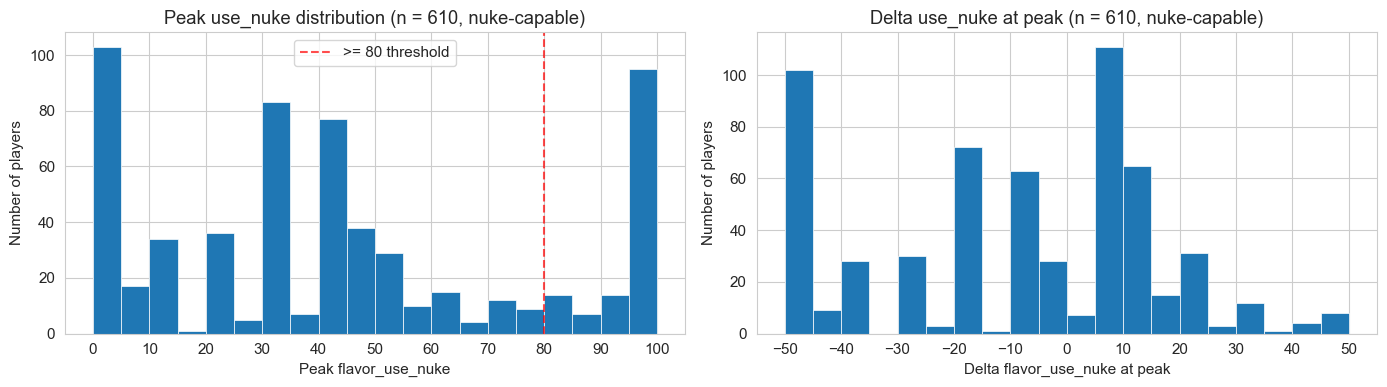

Players with peak use_nuke >= 80: 130 / 610


In [ ]:
# Histograms of full distribution (before >= 80 filter)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(all_peaks['after_use_nuke'], bins=range(0, 105, 5), edgecolor='white', linewidth=0.5)
axes[0].axvline(80, color='red', linestyle='--', alpha=0.7, label='>= 80 threshold')
axes[0].set_xlabel('Peak flavor_use_nuke')
axes[0].set_ylabel('Number of players')
axes[0].set_title(f'Peak use_nuke distribution (n = {len(all_peaks):,}, nuke-capable)')
axes[0].set_xticks(range(0, 105, 10))
axes[0].legend()

axes[1].hist(all_peaks['delta_use_nuke'], bins=range(-50, 55, 5), edgecolor='white', linewidth=0.5)
axes[1].set_xlabel('Delta flavor_use_nuke at peak')
axes[1].set_ylabel('Number of players')
axes[1].set_title(f'Delta use_nuke at peak (n = {len(all_peaks):,}, nuke-capable)')
axes[1].set_xticks(range(-50, 55, 10))

plt.tight_layout()
plt.show()

# Apply >= 80 filter for downstream analysis
first_peak = all_peaks[all_peaks['after_use_nuke'] >= 80].copy()
print(f'Players with peak use_nuke >= 80: {len(first_peak):,} / {len(all_peaks):,}')

In [ ]:
pd.set_option('display.max_colwidth', None)

cols = ['civilization', 'turn', 'after_use_nuke', 'grand_strategy', 'rationale']
left_align = lambda df: df.style.set_properties(subset=['rationale'], **{'text-align': 'left'})

for model, grp in first_peak.groupby('player_type'):
    total = total_per_model.get(model, len(grp))
    nuke = nuke_capable_per_model.get(model, '?')
    pct = 100 * len(grp) / nuke if nuke else 0
    print(f'\n{"="*80}')
    print(f'  {model}  ({len(grp)} / {nuke} nuke-capable, {total} total, {pct:.1f}%)')
    print(f'{"="*80}')
    top5 = grp.nlargest(5, 'after_use_nuke')[cols].copy()
    top5['after_use_nuke'] = top5['after_use_nuke'].astype(int)
    display(left_align(top5.reset_index(drop=True)))


  Deepseek-3.2-Briefed  (2 / 33 nuke-capable, 113 total, 6.1%)


,civilization,turn,after_use_nuke,grand_strategy,rationale
0,The Maya,391,100,Conquest,Egypt is 6/6 on cultural victory and India is nearing diplomatic victory. We must accelerate nuclear production to strike Thebes and disrupt Egypt's tourism. Increasing Nuke and UseNuke to 100 ensures maximum priority for atomic bomb construction and deployment. High Production and Gold flavors support rushing Manhattan Project and buying bombs if possible. Espionage at 100 aids sabotage of cultural progress. Maintaining high military flavors prepares for conventional assaults on Egypt and India.
1,Poland,387,100,Conquest,"We are in the final push for domination victory. We must capture Moson Kahni and London. To achieve this, we need to prioritize building transport ships for amphibious assault and achieve air superiority. Maximizing flavors for naval, air, mobile, and nuclear units ensures the in-game AI focuses production on these critical areas. Deprioritizing non-essential areas like culture, religion, and expansion concentrates our efforts on military conquest."



  Deepseek-3.2-Simple  (20 / 38 nuke-capable, 113 total, 52.6%)


,civilization,turn,after_use_nuke,grand_strategy,rationale
0,Siam,445,100,UnitedNations,"Maximizing UseNuke to 100 ensures our atomic bombs and future nuclear missiles are used aggressively against The Celts' military concentrations and cities, given their overwhelming advantage. Maintaining high Air, Naval, and Nuke flavors sustains our technological edge and production focus. Diplomacy and Espionage at 100 are critical for city-state alliances and spy missions to gain delegates for diplomatic victory. Gold and Science remain top priorities to fund our war effort and tech progression. Other military flavors are tuned for a multi-front defensive-offensive war against The Celts, Germany, and Ethiopia."
1,Spain,400,100,Conquest,"Increase UseNuke to 100 to ensure aggressive nuclear strikes when we initiate war with Russia. Our atomic bomb production is nearing completion, and we want to leverage our nuclear arsenal decisively for swift capital captures."
2,France,413,100,Conquest,We are researching Atomic Theory next to unlock nuclear weapons. Setting Nuke and UseNuke flavors to 100 ensures we prioritize building nukes and are willing to use them strategically once available. This will be crucial for breaking Germany's heavily fortified coastal capitals (Berlin and Beijing) and accelerating the endgame. Other military flavors remain high to sustain our overwhelming conventional advantage.
3,Denmark,495,100,Conquest,"Diplomatic victory is imminent (2 turns), but we must prepare for contingencies. Maximizing Offense, UseNuke, and Air ensures aggressive nuclear and conventional strikes to recapture Indonesian capitals (Honolulu 17%, London 68%) and prevent their domination victory. Slight Diplomacy boost helps secure city-state alliances through the vote. All other flavors remain at previous high levels to maintain total war footing."
4,Greece,401,100,Conquest,Maximize nuclear weapon production and willingness to use them to break enemy defenses and accelerate domination victory. All other military flavors remain high to sustain multi-front warfare.



  GLM-4.7-Briefed  (5 / 69 nuke-capable, 179 total, 7.2%)


...

,civilization,turn,after_use_nuke,grand_strategy,rationale
0,Poland,410,100,Culture,Maximize cultural victory push during Golden Age (14 turns remaining). Already 6/7 influential - Ottomans becoming influential in 24-68 turns. Prioritize Great People generation for tourism and maintain WC coalition diplomacy.
1,Indonesia,395,90,Conquest,Increasing nuclear focus to prepare for potential use against Japan once Rocketry completes. Japan's military superiority (13162 vs 7035) and recent peace with The Iroquois demands stronger deterrent posture.



  Qwen-3.5-Simple  (3 / 25 nuke-capable, 76 total, 12.0%)


,civilization,turn,after_use_nuke,grand_strategy,rationale
0,Assyria,484,100,Conquest,"TURN 484: CRITICAL - Iroquois declared war on us along with 4 city-state allies (Kabul, Venezia, Prague, Samarkand). We face 5+ enemies simultaneously with military severely outnumbered (our 1,139 vs Iroquois 41k, Ottomans 12k, Aztecs 9k). Maintaining maximum Defense/Mobilization for survival. Nuke flavors at 100% - need nuclear deterrent against overwhelming forces. Iroquois at 46 delegates (needs 43) with 16 turns remaining - existential diplomatic threat. Must conquer their city-state allies to flip delegates while defending our cities. Germany (15) + Mongolia (15) alliance critical to block Iroquois World Congress proposals."
1,The Zulus,389,100,Conquest,"Final domination push configuration. Offense/Mobilization/Nuke at 100% for maximum military production and nuclear strike capability against Brazil/Babylon/Rome capitals. Air/Antiair at 100/95 to counter enemy bombers and maintain air superiority. Mobile/Ranged at 100/95 for mechanized infantry and bazooka pushes. Production/Science at 100% to sustain war machine and complete Nuclear Fission tree. Espionage at 90% to rig World Congress elections (9 turns remaining, we trail Brazil 16-17). Expansion/Wonder at 0% - no new cities needed, only conquest of remaining 3 capitals."
2,Indonesia,425,90,UnitedNations,UNITED NATIONS VICTORY PUSH - 10 TURNS TO VOTE: Religion(100) critical for Wittenberg Hinduism quest completion (~3 turns remaining). Diplomacy(100) essential to protect 4 city-state allies providing 8 delegates. Defense(95) and CityDefense(95) prioritize protecting territories during active wars with Aztecs/Shoshone while Iroquois looms. Nuke(95) and UseNuke(90) for deterrence against Iroquois superiority. Antiair(90) and Air(85) counter Iroquois air dominance near coastal cities. Gold(90) funds diplomatic units and city-state gifts. Low Expansion(5) and Wonder(15) - no time for settling/wonders before vote. Low Offense(15) - defensive posture while managing multiple conflicts.



  Sonnet-4.5-Simple  (1 / 15 nuke-capable, 28 total, 6.7%)


,civilization,turn,after_use_nuke,grand_strategy,rationale
0,Sweden,386,90,Conquest,"Maintaining Conquest strategy with adjustments for nuclear-enabled endgame. Advanced Ballistics now allows tactical nuclear strikes against fortified capitals Onondaga and Amsterdam. Increasing UseNuke from 80→90 to enable decisive nuclear employment when conventional assault proves costly. Keeping Offense 80, Mobilization 72, and Nuke 80 for combined arms operations. Montreal at 35% health indicates current force composition is effective. Mobile Tactics (9 turns) will provide Mechanized Infantry for exploitation. With 62% domination progress and overwhelming 5:1 military superiority, this is the final push phase requiring maximum offensive pressure while maintaining strategic nuclear deterrence option."


In [ ]:
import os

os.makedirs('original', exist_ok=True)

for model, grp in first_peak.groupby('player_type'):
    total = total_per_model.get(model, len(grp))
    nuke = nuke_capable_per_model.get(model, 0)
    shown = len(grp)
    vals = grp['after_use_nuke'].astype(int)

    pct_nuke = 100 * nuke / total if total else 0
    pct_shown = 100 * shown / nuke if nuke else 0

    lines = [
        f'# Peak Use Nuke Rationale — {model}\n\n',
        f'- **{total}** total {model} players\n',
        f'- **{nuke}** nuke-capable ({pct_nuke:.1f}% of total)\n',
        f'- **{shown}** with peak `use_nuke` >= 80 ({pct_shown:.1f}% of nuke-capable)\n\n',
        f'Peak values — median: {int(vals.median())}, mean: {vals.mean():.1f}, max: {vals.max()}, min: {vals.min()}\n\n',
        '---\n',
    ]

    for _, row in grp.sort_values('turn').iterrows():
        pv = int(row.prev_use_nuke)
        fv = int(row.after_use_nuke)
        rationale = str(row.rationale).replace('\n', ' ').strip()
        lines.append(f'\n**{row.civilization}** · use_nuke = {pv} => {fv} · Turn {int(row.turn)} · {row.grand_strategy}\n\n')
        lines.append(f'> {rationale}\n')

    slug = model.replace(' ', '_')
    out_path = f'original/{slug}.md'
    with open(out_path, 'w', encoding='utf-8') as f:
        f.writelines(lines)
    print(f'Written: {out_path}')

# CSV export
csv_cols = [
    'game_id', 'player_id', 'turn', 'player_type',
    'prev_use_nuke', 'after_use_nuke',
    'prev_nuke', 'flavor_nuke',
    'rationale',
]
csv_path = 'original/peak_escalations.csv'
first_peak.sort_values(['game_id', 'player_id', 'turn'])[csv_cols].rename(
    columns={'flavor_nuke': 'after_nuke'}
).to_csv(csv_path, index=False)
print(f'Written: {csv_path}  ({len(first_peak)} rows)')

Written: original/Deepseek-3.2-Briefed.md
Written: original/Deepseek-3.2-Simple.md
Written: original/GLM-4.7-Briefed.md
Written: original/GLM-4.7-Simple.md
Written: original/GPT-OSS-120B-Simple.md
Written: original/Kimi-K2.5-Briefed.md
Written: original/Kimi-K2.5-Simple.md
Written: original/Minimax-M2.5-Simple.md
Written: original/Qwen-3.5-Simple.md
Written: original/Sonnet-4.5-Simple.md
Written: original/peak_escalations.csv  (130 rows)
